In [2]:
import sys

import torch

print(sys.executable)
print(torch.__version__, torch.backends.mps.is_available())

/Users/victorialiu/code/cardiac-mri-segmentation/.venv/bin/python
2.15.0 True


# Exploring the ACDC dataset

Goal: understand what one patient's data looks like before building anything.
Each patient has two labelled 3D scans (ED and ES), each a stack of 2D short-axis slices,
plus a mask where 0 = background, 1 = right ventricle, 2 = myocardium, 3 = left ventricle.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from matplotlib.colors import ListedColormap

patient_dir = Path("../data/acdc/training/patient001")

info = {}
for line in (patient_dir / "Info.cfg").read_text().splitlines():
    key, value = line.split(":")
    info[key.strip()] = value.strip()

print(info)
ed_frame = int(info["ED"])
es_frame = int(info["ES"])
print(
    f"ED is frame {ed_frame}, ES is frame {es_frame}, out of {info['NbFrame']} frames"
)

Matplotlib is building the font cache; this may take a moment.


{'ED': '1', 'ES': '12', 'Group': 'DCM', 'Height': '184.0', 'NbFrame': '30', 'Weight': '95.0'}
ED is frame 1, ES is frame 12, out of 30 frames


In [5]:
def load(frame: int, mask: bool = False) -> nib.Nifti1Image:
    suffix = "_gt" if mask else ""
    return nib.load(patient_dir / f"{patient_dir.name}_frame{frame:02d}{suffix}.nii.gz")


ed_img = load(ed_frame)
ed_mask = load(ed_frame, mask=True)

image = ed_img.get_fdata()
mask = ed_mask.get_fdata().astype(np.uint8)

print("shape (width, height, slices):", image.shape)
print("voxel size in mm:", ed_img.header.get_zooms())
print("intensity range:", image.min(), "to", image.max())
print("labels in mask:", np.unique(mask))

shape (width, height, slices): (216, 256, 10)
voxel size in mm: (np.float32(1.5625), np.float32(1.5625), np.float32(10.0))
intensity range: 0.0 to 658.0
labels in mask: [0 1 2 3]


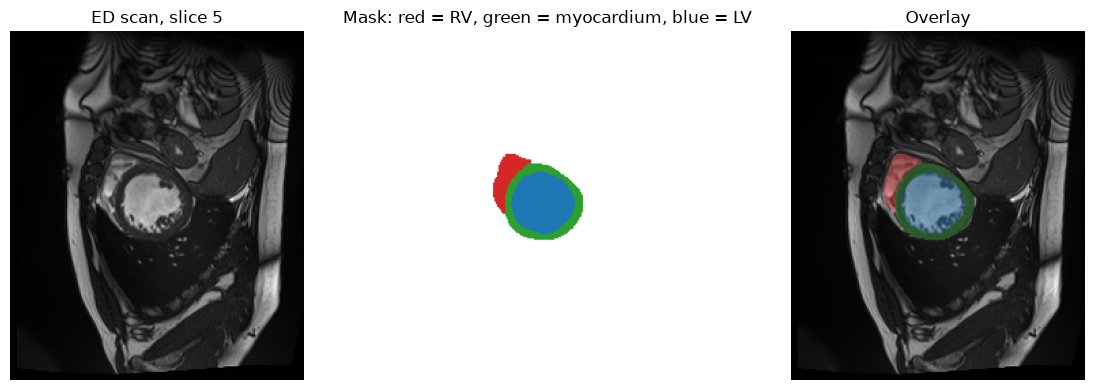

In [6]:
z = image.shape[2] // 2
mask_colors = ListedColormap(["none", "tab:red", "tab:green", "tab:blue"])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title(f"ED scan, slice {z}")
axes[1].imshow(mask[:, :, z].T, cmap=mask_colors, vmin=0, vmax=3, origin="lower")
axes[1].set_title("Mask: red = RV, green = myocardium, blue = LV")
axes[2].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[2].imshow(
    mask[:, :, z].T, cmap=mask_colors, vmin=0, vmax=3, alpha=0.4, origin="lower"
)
axes[2].set_title("Overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

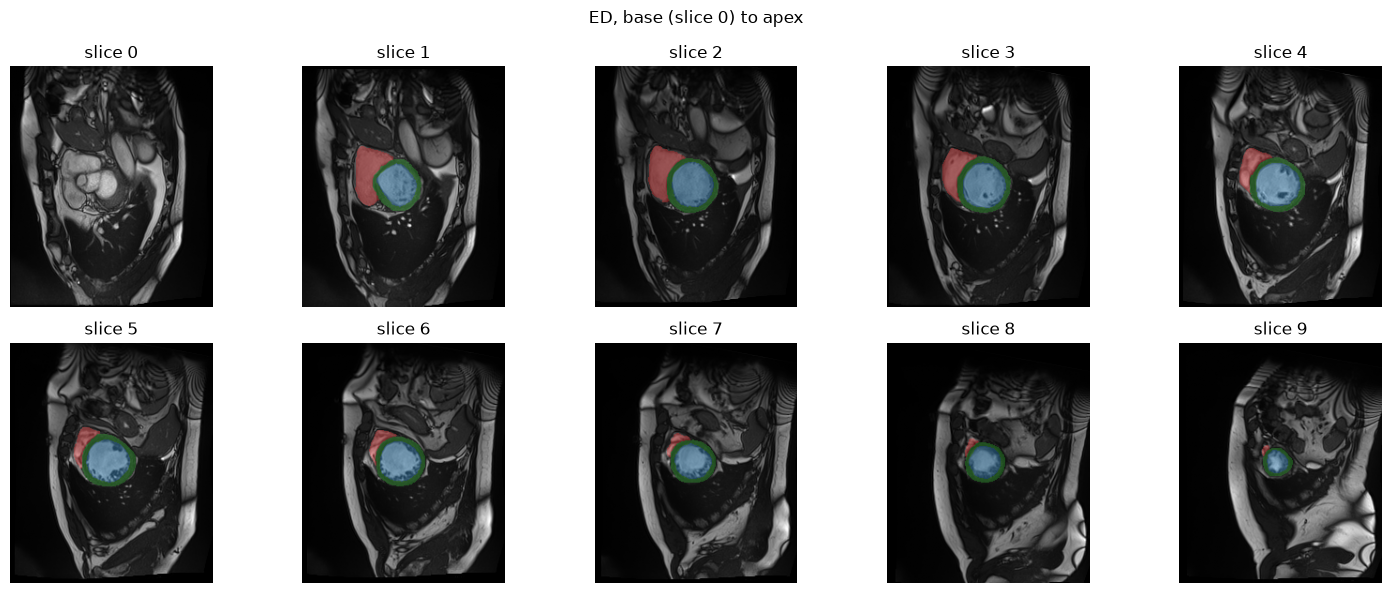

In [7]:
n_slices = image.shape[2]
cols = 5
rows = int(np.ceil(n_slices / cols))

fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
for z, ax in enumerate(axes.flat):
    ax.axis("off")
    if z >= n_slices:
        continue
    ax.imshow(image[:, :, z].T, cmap="gray", origin="lower")
    ax.imshow(
        mask[:, :, z].T, cmap=mask_colors, vmin=0, vmax=3, alpha=0.4, origin="lower"
    )
    ax.set_title(f"slice {z}")
fig.suptitle("ED, base (slice 0) to apex")
plt.tight_layout()
plt.show()

one voxel = 24.4 mm^3
LV volume at ED (EDV): 295.5 mL
LV volume at ES (ESV): 225.6 mL
Ejection fraction: 23.7%   (healthy is roughly 55-70%; this patient's group: DCM)


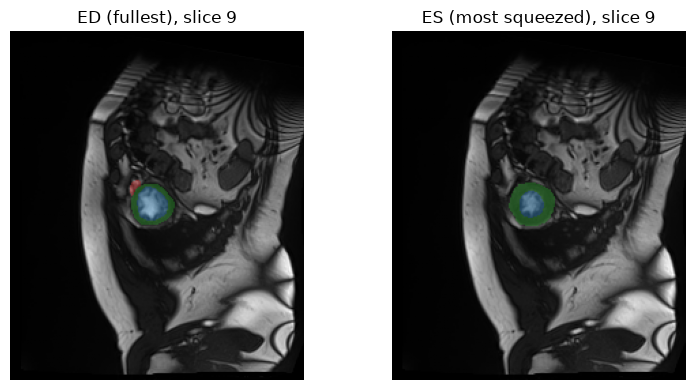

In [9]:
es_img = load(es_frame)
es_mask = load(es_frame, mask=True).get_fdata().astype(np.uint8)

voxel_ml = np.prod(ed_img.header.get_zooms()) / 1000
edv = (mask == 3).sum() * voxel_ml
esv = (es_mask == 3).sum() * voxel_ml
ef = (edv - esv) / edv * 100

print(f"one voxel = {voxel_ml * 1000:.1f} mm^3")
print(f"LV volume at ED (EDV): {edv:.1f} mL")
print(f"LV volume at ES (ESV): {esv:.1f} mL")
print(
    f"Ejection fraction: {ef:.1f}%   (healthy is roughly 55-70%; this patient's group: {info['Group']})"
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, img, m, name in [
    (axes[0], image, mask, "ED (fullest)"),
    (axes[1], es_img.get_fdata(), es_mask, "ES (most squeezed)"),
]:
    ax.imshow(img[:, :, z].T, cmap="gray", origin="lower")
    ax.imshow(m[:, :, z].T, cmap=mask_colors, vmin=0, vmax=3, alpha=0.4, origin="lower")
    ax.set_title(f"{name}, slice {z}")
    ax.axis("off")
plt.tight_layout()
plt.show()